In [80]:
# lo so è pieno di roba inutile

import numpy as np
import pandas as pd
from itertools import cycle
from matplotlib.path import Path as MplPath
import tifffile as tiff
import sys
from pathlib import Path
import plotly.graph_objects as go

# stolen from phasor.py
from phasorpy.plot import PhasorPlot  
from phasorpy.datasets import fetch

# personal stuff
import random
import scipy.stats as stats
import matplotlib.pyplot as plt
from iminuit import Minuit, cost

import lib.randgen
import lib.my_stats


# 1. Exponential data generation

In [81]:
τ_true = 4 # ns
N_evt = 10000
T_laser = 12.5  #ns

exp1data = np.random.exponential(scale = τ_true, size = N_evt) % T_laser   # exp1data = SINGLE exponential data
time_bins = np.linspace(0, T_laser, 4096)
n, _ = np.histogram(exp1data, bins = time_bins)
    # xe = bin edges, n = bin heights
    # Removed xe bc I'm using time_bins to calculate bins

# Annotation: in line 5, / T_laser is used


<h3> Binned NNL fit (only made for comparison purposes)

In [82]:
def expon_cdf(x, A, τ):
    return A * τ * (1.0 - np.exp(-x / τ))   # I need cdf for the binned likelihood 

#fixing crazy chi squared results
A_guess, tau_guess = n[0], np.mean(exp1data)

c_binned = cost.ExtendedBinnedNLL(n, time_bins, expon_cdf)
m = Minuit(c_binned, A = A_guess, τ = tau_guess)
m.limits["τ"], m.limits["A"] = (0.001, None), (0.001, None)     # placing lower limits on both parameters to avoid negative values
m.migrad()

print("Params")
# if i dont leave an empty line, params will not display for some reason
display(m.params)

print("\nStats")
lib.my_stats.minuit_stats(m)

# help now pval is always 0 because of too many bins... 


Params


,Name,Value,Hesse Error,Minos Error-,Minos Error+,Limit-,Limit+,Fixed
0,A,2.67e3,0.04e3,,,0.001,,
1,τ,3.90,0.05,,,0.001,,



Stats
chi-squared: 4426.38
reduced chi-squared: 1.08
dof: 4093.00
p-value: 0.00


# 2. Phasor plot and noise addition

Functions for calculating and plotting phasors (given a histogram)

In [83]:
def phasor_calc (n, harm_n = 1):   # given a histogram n (xe), calculates the phasor coordinates G and S

    fft_vals = np.fft.rfft(n)
    fft_norm = fft_vals / fft_vals[0]
    
    G, S = np.real(fft_norm[harm_n]), -np.imag(fft_norm[harm_n])

    return G, S




###################################################################################################



def add_noise(counts, snr_db):  # Adds GAUSSIAN NOISE (why not Poisson? Need to check)

    rng = np.random.default_rng()   
    snr_linear = 10 ** (snr_db / 10)  # convert SNR from dB to linear scale 

    sig_power = np.mean(counts ** 2, axis = 0) 
    noise_std = np.sqrt(sig_power / snr_linear)
    noise = rng.standard_normal(counts.shape) * noise_std
    
    return np.clip(counts + noise, 0, None)




###################################################################################################


def phasor_calc_mix(G_array, S_array, fractions):

    fractions = fractions / np.sum(fractions)  # safety feature
    G_mix, S_mix = np.sum(fractions * G_array), np.sum(fractions * S_array)
    
    return G_mix, S_mix

In [84]:
#plotting functions

def data_and_phasor_plot(xe, n, G, S, T_laser, exp1data):

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (14, 5))

    # hist + plot
    bin_centers = 0.5 * (xe[:-1] + xe[1:])    # select bin centers

    # use the following line with a lower binning to show a clearer histogram of the data
    # ax1.hist(exp1data, bins = xe, density = False, alpha = 0.3, color = 'steelblue', edgecolor = 'midnightblue', label = 'Data')

    ax1.plot(bin_centers, n, color = 'purple', marker = '', linestyle = '-', linewidth = 1.5)

    ax1.set_xlabel('t (ns)', fontsize = 12)
    ax1.set_ylabel('counts', fontsize = 12)
    # ax1.legend(fontsize = 11, frameon = True, shadow = True)
    ax1.grid(True, which = "both", linestyle = "--", alpha = 0.5)
    ax1.set_xlim(0, xe[-1])



    # phasor plane
    ω_laser = 1000.0 / T_laser  # Calcolo della frequenza in MHz
    plot = PhasorPlot(frequency = ω_laser, ax = ax2)

    plot.plot([G], [S], marker = 'x', markersize = 10, markeredgewidth = 2, 
              color = 'purple', label = 'Fasore (Dati)')

    #ax2.legend(loc = 'upper right', fontsize = 11, frameon = True, shadow = True)

    # ax1.set_yscale('log')         #  looks terrible for some reason

    plt.tight_layout()
    plt.show()



#######################################################################################################



def plot_decay(xe, n):                  # plots exponential data alone

    fig, ax = plt.subplots(figsize=(7, 5))
    t = 0.5 * (xe[:-1] + xe[1:])

    ax.step(t, n, where = 'mid', color = 'purple', linewidth = 1.5)
    ax.set(xlabel = 't (ns)', ylabel = 'counts')
    ax.grid(alpha = 0.3)
    plt.yscale('log')

    plt.tight_layout()
    plt.show()


#####################################################################################################




def universal_phasor_plot(T_laser, points, lines = None, figsize = (8, 8)):     # Plots every single phasor plot imaginable

    """    
    - points: dict list for markers [{'G': 0.5, 'S': 0.4, 'label': 'IRF', 'color': 'darkorange', 'marker': 'o'}]
    - lines: dict list for lines [{'G': [G1, G2], 'S': [S1, S2], 'color': 'gray', 'ls': '--'}]
    """

    fig, ax = plt.subplots(figsize = figsize)

    ω_laser = 1000.0 / T_laser
    plot = PhasorPlot(frequency = ω_laser, ax = ax)
    
    #LINES 
    if lines:
        for line in lines:
            line_style = line.copy()
            G_coords = line_style.pop('G')
            S_coords = line_style.pop('S')

            line_style.setdefault('zorder', 1) 
            
            ax.plot(G_coords, S_coords, **line_style)
            
    # MARKERS 
    for pt in points:
        pt_style = pt.copy()
        G_val = pt_style.pop('G')
        S_val = pt_style.pop('S')
        
        pt_style.setdefault('marker', 'o')
        pt_style.setdefault('markersize', 8)
        pt_style.setdefault('zorder', 3)
        
        plot.plot([G_val], [S_val], **pt_style)
        
    # Cosmetic stuff
    ax.set_xlabel('G, real', fontsize = 12)
    ax.set_ylabel('S, imaginary', fontsize = 12)
    ax.legend(loc='upper right', frameon = True, fontsize = 11, shadow = True)

    plt.tight_layout()
    plt.show()


<h3> Single exponential

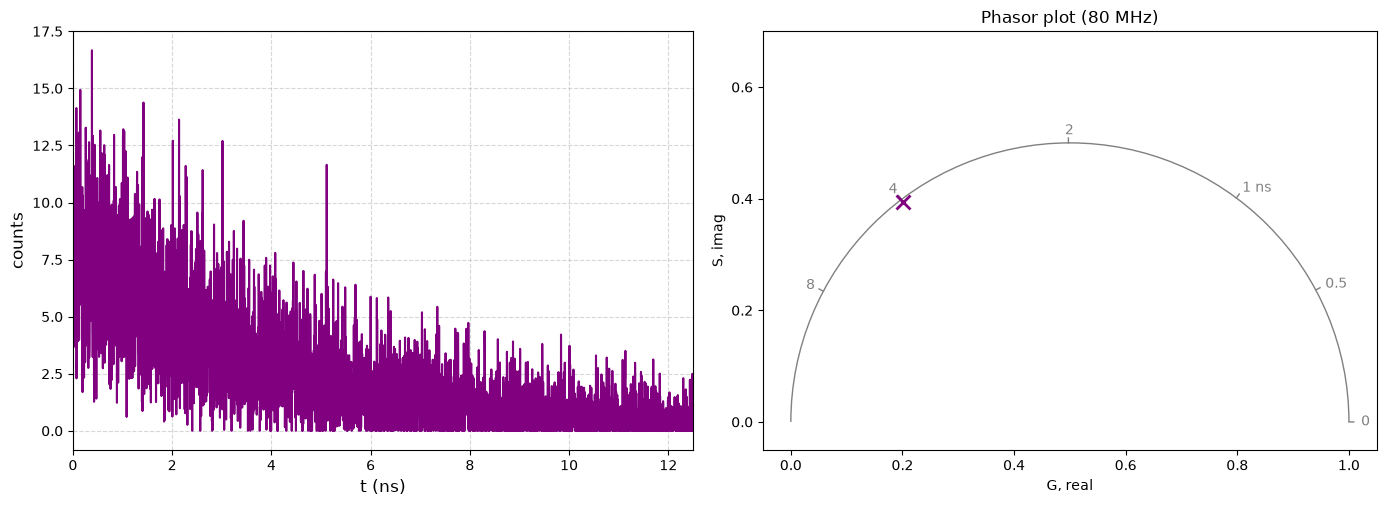

In [85]:
noise_bool = True     # toggle to add noise
if noise_bool: n = add_noise(n, snr_db = 20)   # higher snr = less noise

#phasors = [phasor_calc(n, harm_n) for harm_n in range(1, 4)]  # calculate phasors for the first three harmonics
#data_and_phasor_plot(xe, n, phasors[0][0], phasors[0][1], T_laser=12.5)  # [0][1] = first harmonic, S

phasors = phasor_calc(n)   # commented the version that displays multiple harmonics
data_and_phasor_plot(time_bins, n, phasors[0], phasors[1], T_laser, exp1data)


<h3> Double exponential

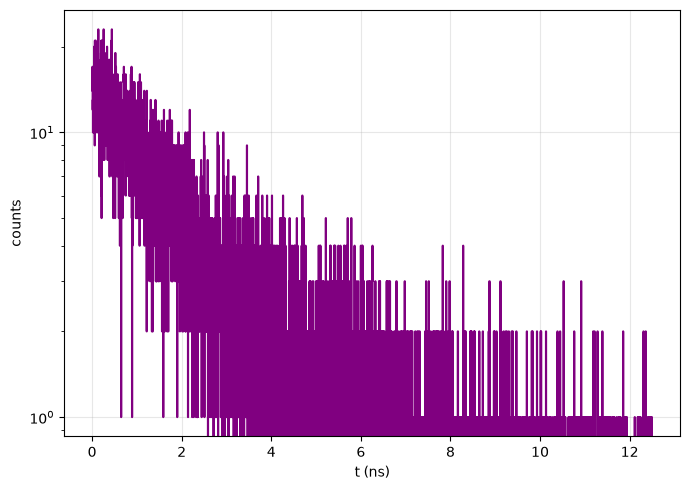

In [86]:
# Usual stuff, now for 2 curves

τ_true1, τ_true2 = 1.5, 4.0
f1 = 0.6    # ratio of intensity for the 2 curves

N_evt1 = int(N_evt * f1)   # ratio of events for the 2 curves 
N_evt2 = N_evt - N_evt1

exp2data1 = np.random.exponential(scale = τ_true1, size = N_evt1)
exp2data2 = np.random.exponential(scale = τ_true2, size = N_evt2)

time_bins = np.linspace(0, T_laser, 4096)
t = 0.5 * (time_bins[:-1] + time_bins[1:])

n1, _ = np.histogram(exp2data1 % T_laser, bins = time_bins)
n2, _ = np.histogram(exp2data2 % T_laser, bins = time_bins)
n_mix = n1 + n2  


plot_decay(time_bins, n_mix)

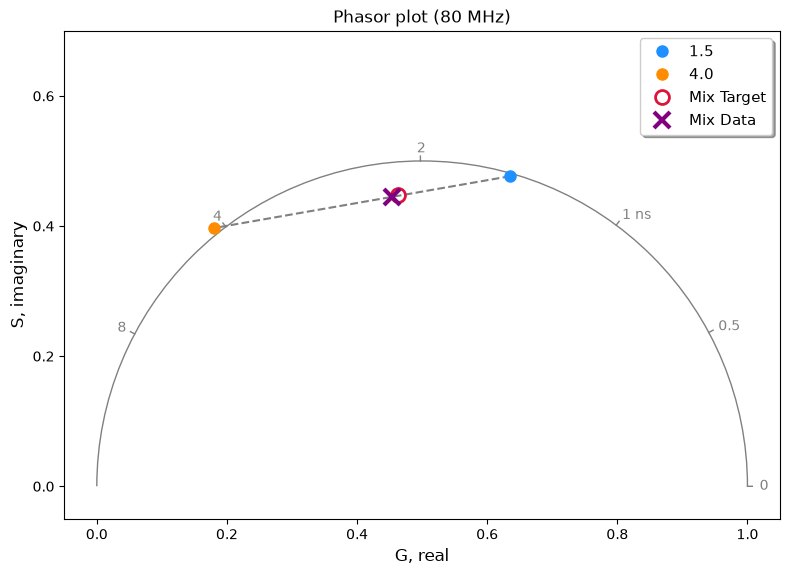

In [87]:
(G1, S1), (G2, S2), (G_mix, S_mix) = map(phasor_calc, (n1, n2, n_mix))              # G1, G2 = phasor_calc(n1), etc
(G1_true, S1_true), (G2_true, S2_true) = map(phasor_calc, (np.exp(-t / τ_true1), np.exp(-t / τ_true2)))    # Here n values are taken from pure exponential in t

G_true, S_true = phasor_calc_mix([G1_true, G2_true], [S1_true, S2_true], [f1, 1 - f1])

points_mix = [
    {'G': G1, 'S': S1, 'label': f'{τ_true1}', 'color': 'dodgerblue'},
    {'G': G2, 'S': S2, 'label': f'{τ_true2}', 'color': 'darkorange'},
    {'G': G_true, 'S': S_true, 'label': 'Mix Target', 'marker': 'o', 'markerfacecolor': 'none', 'markeredgecolor': 'crimson', 'markeredgewidth': 2, 'markersize': 10, 'zorder': 2},
    {'G': G_mix, 'S': S_mix, 'label': 'Mix Data', 'color': 'purple', 'marker': 'x', 'markersize': 12, 'markeredgewidth': 3, 'zorder': 3}
]
lines_mix = [
    {'G': [G1, G2], 'S': [S1, S2], 'color': 'gray', 'ls': '--', 'lw': 1.5}
]

universal_phasor_plot(T_laser, points = points_mix, lines = lines_mix)

<h3> double/triple exponential

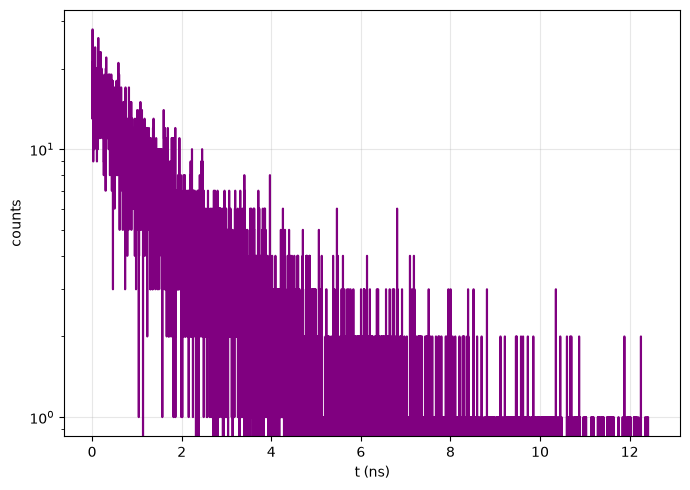

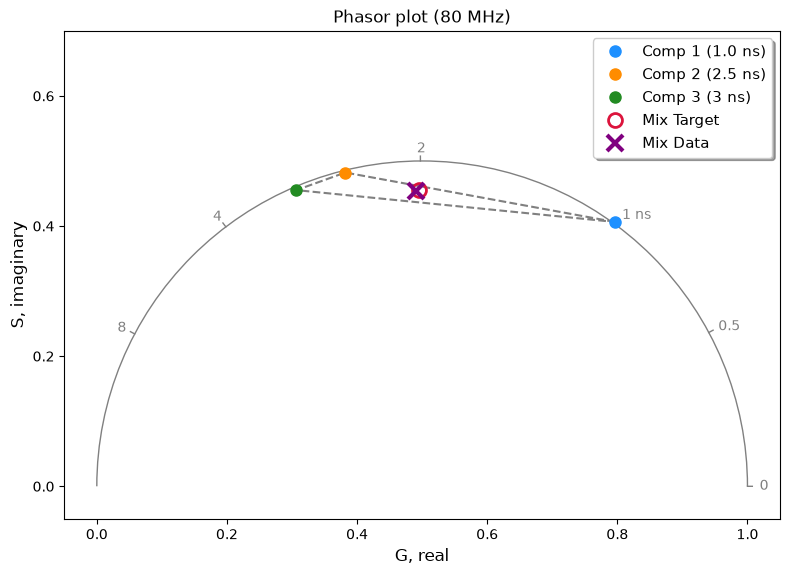

In [88]:
n_comp = 3           # MASTER SWITCH: 2 or 3 components

if n_comp == 2:
    
    τ_true1, τ_true2 = 1.5, 4.0
    f1 = 0.6
    f2 = 1.0 - f1

    N_evt1, N_evt2 = int(N_evt * f1), int(N_evt * f2)
    N_evt3 = N_evt - N_evt1 - N_evt2

    expdata1 = np.random.exponential(scale=τ_true1, size=N_evt1)
    expdata2 = np.random.exponential(scale=τ_true2, size=N_evt2)

    n1, _ = np.histogram(expdata1 % T_laser, bins=time_bins)
    n2, _ = np.histogram(expdata2 % T_laser, bins=time_bins)
    n_mix = n1 + n2

    (G1, S1), (G2, S2), (G_mix, S_mix) = map(phasor_calc, (n1, n2, n_mix))
    (G1_true, S1_true), (G2_true, S2_true) = map(phasor_calc, (np.exp(-t/τ_true1), np.exp(-t/τ_true2)))
    
    G_true, S_true = phasor_calc_mix([G1_true, G2_true], [S1_true, S2_true], [f1, f2])

    points_mix = [
        {'G': G1, 'S': S1, 'label': f'Comp 1 ({τ_true1} ns)', 'color': 'dodgerblue'},
        {'G': G2, 'S': S2, 'label': f'Comp 2 ({τ_true2} ns)', 'color': 'darkorange'},
        {'G': G_true, 'S': S_true, 'label': 'Mix Target', 'marker': 'o', 'markerfacecolor': 'none', 'markeredgecolor': 'crimson', 'markeredgewidth': 2, 'markersize': 10, 'zorder': 2},
        {'G': G_mix, 'S': S_mix, 'label': 'Mix Data', 'color': 'purple', 'marker': 'x', 'markersize': 12, 'markeredgewidth': 3, 'zorder': 3}
    ]
    lines_mix = [
        {'G': [G1, G2], 'S': [S1, S2], 'color': 'gray', 'ls': '--', 'lw': 1.5}
    ]


elif n_comp == 3:

    τ_true1, τ_true2, τ_true3 = 1.0, 2.5, 3
    f1, f2 = 0.3, 0.5 
    f3 = 1.0 - f1 - f2

    N_evt1, N_evt2 = int(N_evt * f1), int(N_evt * f2)
    N_evt3 =  N_evt - N_evt1 - N_evt2

    expdata1 = np.random.exponential(scale=τ_true1, size=N_evt1)
    expdata2 = np.random.exponential(scale=τ_true2, size=N_evt2)
    expdata3 = np.random.exponential(scale=τ_true3, size=N_evt3)

    n1, _ = np.histogram(expdata1 % T_laser, bins=time_bins)
    n2, _ = np.histogram(expdata2 % T_laser, bins=time_bins)
    n3, _ = np.histogram(expdata3 % T_laser, bins=time_bins)
    n_mix = n1 + n2 + n3

    (G1, S1), (G2, S2), (G3, S3), (G_mix, S_mix) = map(phasor_calc, (n1, n2, n3, n_mix))
    (G1_true, S1_true), (G2_true, S2_true), (G3_true, S3_true) = map(
        phasor_calc, (np.exp(-t/τ_true1), np.exp(-t/τ_true2), np.exp(-t/τ_true3))
    )
    
    G_true, S_true = phasor_calc_mix([G1_true, G2_true, G3_true], [S1_true, S2_true, S3_true], [f1, f2, f3])

    points_mix = [
        {'G': G1, 'S': S1, 'label': f'Comp 1 ({τ_true1} ns)', 'color': 'dodgerblue'},
        {'G': G2, 'S': S2, 'label': f'Comp 2 ({τ_true2} ns)', 'color': 'darkorange'},
        {'G': G3, 'S': S3, 'label': f'Comp 3 ({τ_true3} ns)', 'color': 'forestgreen'},
        {'G': G_true, 'S': S_true, 'label': 'Mix Target', 'marker': 'o', 'markerfacecolor': 'none', 'markeredgecolor': 'crimson', 'markeredgewidth': 2, 'markersize': 10, 'zorder': 2},
        {'G': G_mix, 'S': S_mix, 'label': 'Mix Data', 'color': 'purple', 'marker': 'x', 'markersize': 12, 'markeredgewidth': 3, 'zorder': 3}
    ]
    lines_mix = [
        {'G': [G1, G2, G3, G1], 'S': [S1, S2, S3, S1], 'color': 'gray', 'ls': '--', 'lw': 1.5}
    ]


plot_decay(time_bins, n_mix)
universal_phasor_plot(T_laser, points=points_mix, lines=lines_mix)

Osservazione: intensità più piccola = errore più grande (ma va?), perché il rumore è generato sempre con la stessa ampiezza e quindi diventa più importante per dati "piccoli"


# 3. Simulation of data + IRF convolution

2 parole su cosa devo fare per vedere se ho capito. Spegazione presa dal file mmc5.pdf

IRF = Instrument Response Function, è la funzione di risposta al laser data dal rivelatore. È fondamentalmente il profilo temporale della risposta del sistema di rilevamento a un impulso laser brevissimo.

Il sistema di rilevamento infatti presenta sempre un errore nella risposta intrinseco dovuto a motivi fisici/elettronici (e quindi non riproducibile).
Studiare l'IRF permette di ottenere informazioni su questo errore e dunque correggere anche i dati raccolti.

Nel piano temporale: decadimento rilevato = convoluzione(decadimento reale, IRF)
Nel piano dei fasori: z_tot = z_exp * z_IRF




<h3> Functions for this section

In [89]:
def irf_generation(σ, μ, counts, T_laser, num_bins = 30):       # gaussian IRF

    time_bins = np.linspace(0, T_laser, num_bins)
    
    irf = np.exp(-((time_bins - μ)**2) / (2 * σ**2))
    
    irf /= np.sum(irf)
    irf *= counts
    
    return time_bins, irf



#############################################################################################################



def simulation_with_IRF(exp1data1, irf, counts, noise_flag, snr_db): 

    n_bins = len(irf)
    
    # Use a circular convolution so the signal stays consistent with the laser period.
    convol = np.fft.ifft(np.fft.fft(exp1data1) * np.fft.fft(irf)).real      # Here I'm using the phasor method instead of 
                                                                            # np.convolve (slow + doesn't handle periodicity)

    convol = np.clip(convol, 0, None)
    convol = (convol / np.sum(convol)) * counts  # Normalization
    
    #NOISEEEEE
    if noise_flag: noisy_signal = add_noise(convol, snr_db) 
    else: noisy_signal = convol
    
    return convol, noisy_signal




##############################################################################################################




def phasor_deconv(G_meas, S_meas, G_irf, S_irf): 
 
    z_meas = G_meas + 1j * S_meas       # imaginary unit i = 1j
    z_irf = G_irf + 1j * S_irf
    
    z_deconvol = z_meas / z_irf       # in phasor plane, convolution = moltiplication
    
    G_deconvol, S_deconvol = np.real(z_deconvol), np.imag(z_deconvol)
    
    return G_deconvol, S_deconvol


<h3> Simulation of binned data (single exponential) + gaussian IRF 

In [90]:
# Testing the functions

T_laser = 12.5
N_evt1 = 10000
τ_true1 = 4       

μ, σ = 0.3, 0.1

exp1data1 = np.random.exponential(scale = τ_true, size = N_evt) % T_laser
time_bins = np.linspace(0, T_laser, 4096)
n1, xe1= np.histogram(exp1data1, bins = time_bins)   

noise_bool1, snr_db1 = True, 20  

time_bins, irf = irf_generation(σ, μ, N_evt1, T_laser, len(n1))

convoluted_signal, noisy_signal = simulation_with_IRF(n1, irf, N_evt1, noise_bool1, snr_db1)


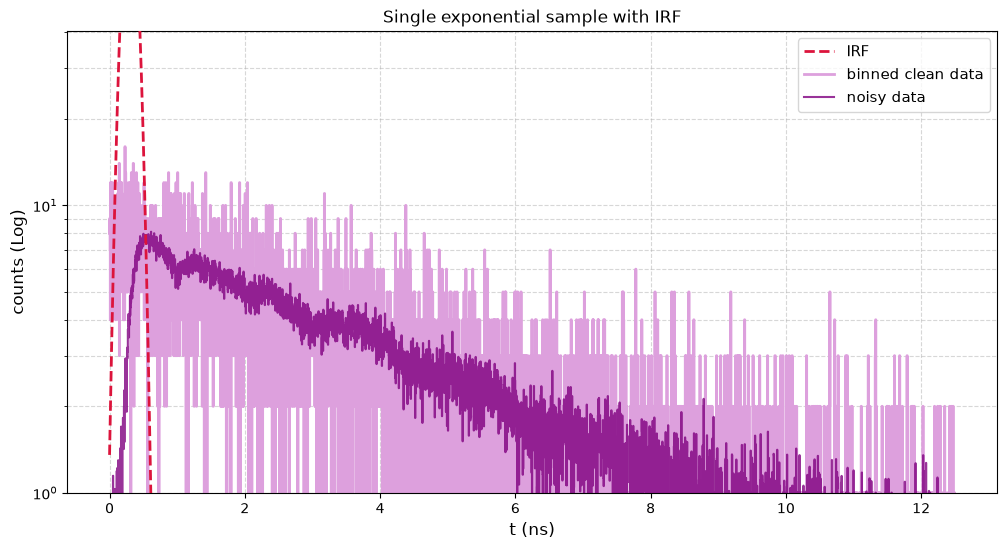

In [91]:
plt.figure(figsize = (12, 6))

signal_max = np.max(noisy_signal)
irf_plot = irf

plt.plot(time_bins, irf_plot, label = 'IRF', color = 'crimson', linestyle = '--', zorder = 3, linewidth = 2)
  
plt.step(xe1[:-1], n1, where = 'mid', label = 'binned clean data', color = 'plum', linewidth = 2)

plt.step(time_bins, noisy_signal, where = 'mid', label = 'noisy data', color = 'purple', alpha = 0.8)

plt.yscale('log')

plt.ylim(bottom = 1, top = signal_max * 5) 

plt.xlabel('t (ns)', fontsize = 12)  
plt.ylabel('counts (Log)', fontsize = 12)
plt.grid(True, which = "both", linestyle = "--", alpha = 0.5)
plt.legend(loc = 'upper right', fontsize = 11)

plt.title('Single exponential sample with IRF')

plt.show()


# È normale che sia così wiggly??

<h3> Deconvolution of signal (single exponential)

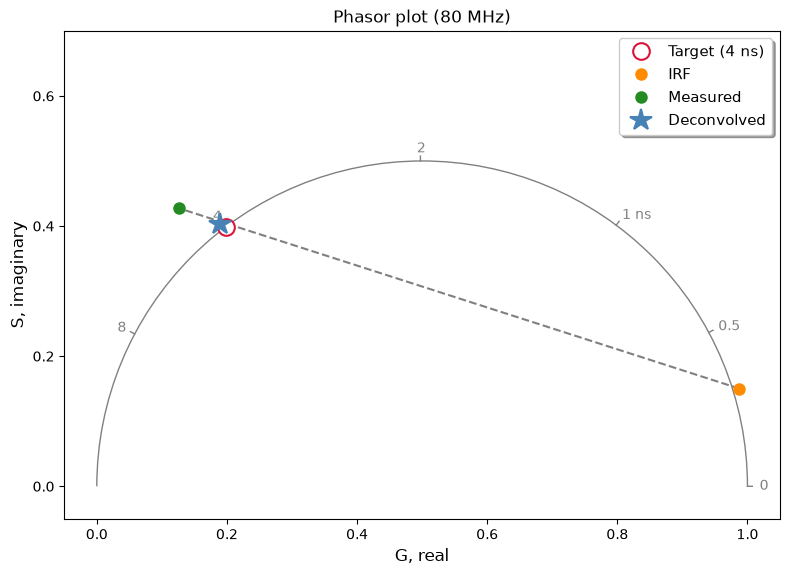

In [92]:
G_meas, S_meas = phasor_calc(noisy_signal, harm_n=1)      # tot signal phasor
G_irf, S_irf = phasor_calc(irf, harm_n=1)     # irf phasor

G_deconvol, S_deconvol = phasor_deconv(G_meas, S_meas, G_irf, S_irf)     # cleaned phasor (deconv of signal and irf)

n_true = np.exp(-t / τ_true)
G_true, S_true = phasor_calc(n_true)

points_mix1 = [
    {
        'G': G_true, 
        'S': S_true, 
        'label': f'Target ({τ_true} ns)', 
        'color': 'crimson', 
        'marker': 'o', 
        'markersize': 12, 
        'markeredgewidth': 1.5, 
        'markerfacecolor': 'white'
    },
    {
        'G': G_irf, 
        'S': S_irf, 
        'label': 'IRF', 
        'color': 'darkorange', 
        'marker': 'o', 
        'markersize': 8
    },
    {
        'G': G_meas, 
        'S': S_meas, 
        'label': 'Measured', 
        'color': 'forestgreen', 
        'marker': 'o', 
        'markersize': 8, 
    },
    {
        'G': G_deconvol, 
        'S': S_deconvol, 
        'label': 'Deconvolved', 
        'color': 'steelblue', 
        'marker': '*', 
        'markersize': 16, 
        'markeredgewidth': 1.5
    }
]

lines_mix1 = [
    {'G': [G_irf, G_meas], 'S': [S_irf, S_meas], 'color': 'gray', 'ls': '--', 'lw': 1.5}
]

universal_phasor_plot(T_laser, points = points_mix1, lines = lines_mix1)

<h3> Simulation of binned data (double exponential) + gaussian IRF 

Here I will be recycling some variables from previous cells. They are commented here so they can be re-defined if necessary

In [93]:
# --- FROM 2-EXP SIMULATION

τ_true1, τ_true2 = 4.0, 2

f1 = 0.7    # ratio of intensity for the 2 curves

N_evt1 = int(N_evt * f1)   # ratio of events for the 2 curves 
N_evt2 = N_evt - N_evt1

exp2data1 = np.random.exponential(scale = τ_true1, size = N_evt1)
exp2data2 = np.random.exponential(scale = τ_true2, size = N_evt2)

time_bins = np.linspace(0, T_laser, 4096)
t = 0.5 * (time_bins[:-1] + time_bins[1:])

n1, _ = np.histogram(exp2data1 % T_laser, bins = time_bins)
n2, _ = np.histogram(exp2data2 % T_laser, bins = time_bins)
n_mix = n1 + n2  


# --- FROM EXP + IRF CONVOLUTION

μ, σ = 0.25, 0.1
noise_bool1, snr_db1 = True, 20  
time_bins, irf = irf_generation(σ, μ, N_evt1, T_laser, len(n1))

convoluted_signal1, noisy_signal1 = simulation_with_IRF(n_mix, irf, N_evt1, noise_bool1, snr_db1)

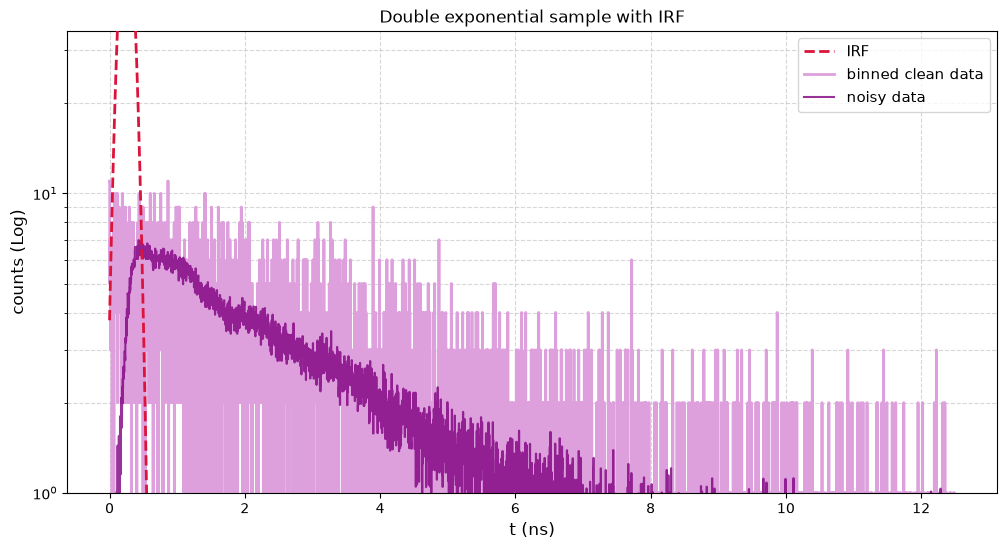

In [94]:
plt.figure(figsize = (12, 6))

signal_max = np.max(noisy_signal1)
irf_plot = irf

plt.plot(time_bins, irf_plot, label = 'IRF', color = 'crimson', linestyle = '--', zorder = 3, linewidth = 2)
  
plt.step(time_bins, n1, where = 'mid', label = 'binned clean data', color = 'plum', linewidth = 2)

plt.step(time_bins, noisy_signal1, where = 'mid', label = 'noisy data', color = 'purple', alpha = 0.8)

plt.yscale('log')

plt.ylim(bottom = 1, top = signal_max * 5) 

plt.xlabel('t (ns)', fontsize = 12)  
plt.ylabel('counts (Log)', fontsize = 12)
plt.grid(True, which = "both", linestyle = "--", alpha = 0.5)
plt.legend(loc = 'upper right', fontsize = 11)
plt.title('Double exponential sample with IRF')

plt.show()

<h3> Deconvolution of signal (double exponential)


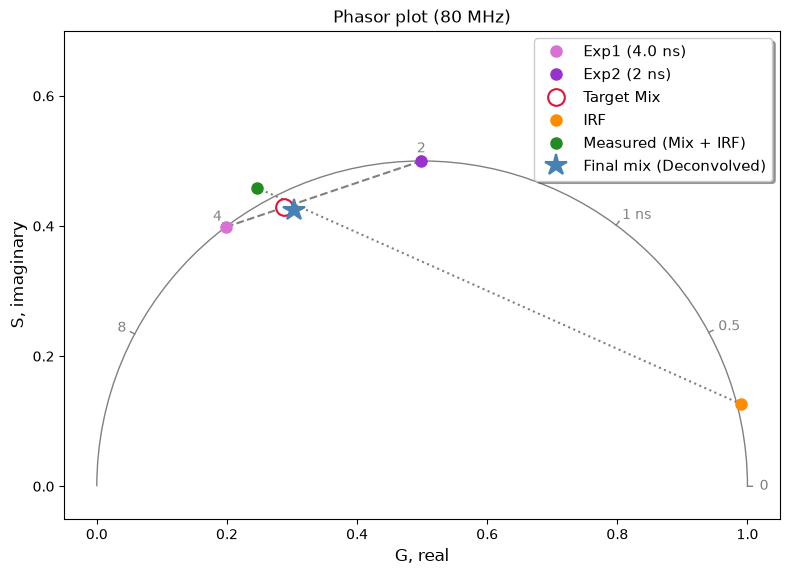

In [95]:
G_irf, S_irf = phasor_calc(irf)
G_meas, S_meas = phasor_calc(noisy_signal1)
G_deconvol, S_deconvol = phasor_deconv(G_meas, S_meas, G_irf, S_irf)

(G1t, S1t), (G2t, S2t) = map(phasor_calc, (np.exp(-t / τ_true1), np.exp(-t / τ_true2)))

G_target, S_target = phasor_calc_mix([G1t, G2t], [S1t, S2t], [f1, 1 - f1])

points_mix2 = [
    {
        'G': G1t, 
        'S': S1t, 
        'label': f'Exp1 ({τ_true1} ns)', 
        'color': 'orchid', 
        'marker': 'o', 
        'markersize': 8
    },
    {
        'G': G2t, 
        'S': S2t, 
        'label': f'Exp2 ({τ_true2} ns)', 
        'color': 'darkorchid', 
        'marker': 'o', 
        'markersize': 8
    },
    {
        'G': G_target, 
        'S': S_target, 
        'label': 'Target Mix', 
        'color': 'crimson', 
        'marker': 'o', 
        'markersize': 12, 
        'markeredgewidth': 1.5, 
        'markerfacecolor': 'white'
    },
    {
        'G': G_irf, 
        'S': S_irf, 
        'label': 'IRF', 
        'color': 'darkorange', 
        'marker': 'o', 
        'markersize': 8
    },
    {
        'G': G_meas, 
        'S': S_meas, 
        'label': 'Measured (Mix + IRF)', 
        'color': 'forestgreen', 
        'marker': 'o', 
        'markersize': 8
    },
    {
        'G': G_deconvol, 
        'S': S_deconvol, 
        'label': 'Final mix (Deconvolved)', 
        'color': 'steelblue', 
        'marker': '*', 
        'markersize': 16, 
        'markeredgewidth': 1.5
    }
]

lines_mix2 = [
    {'G': [G1t, G2t], 'S': [S1t, S2t], 'color': 'gray', 'ls': '--', 'lw': 1.5},
    {'G': [G_irf, G_meas], 'S': [S_irf, S_meas], 'color': 'gray', 'ls': ':', 'lw': 1.5}
]

universal_phasor_plot(T_laser, points = points_mix2, lines = lines_mix2)

# 4. Working on an imported image - incomplete

<h3> Functions for this section

In [96]:
def image_flattener(image):     # 2d image with the amount of photons per pixel in total time

    flat_image = np.sum(image, axis =0)     # sum of total photons

    plt.imshow(flat_image, cmap = 'magma')   # alternatives I like: plasma, viridis, gray
    plt.colorbar(label = 'total counts')

    max_index = np.unravel_index(np.argmax(flat_image), flat_image.shape)      # auto select point with highest counts
                                                                               # the same can be done manually with plotly

    plt.scatter(max_index[1], max_index[0], facecolors = 'none', edgecolors = 'cyan', marker = 'o', 
                s = 100, linewidths = 2, label = f'x = {max_index[1]}, y = {max_index[0]}')

    plt.legend()
    plt.show()

    return max_index



############################################################################################################


def pixel_plot(image, pixel):

    x = np.linspace(0, 12.5, image.shape[0])

    plt.figure(figsize = (17, 5))
    plt.step(x, image[:, pixel[0], pixel[1]], where = 'mid', color = 'plum', linewidth = 1.5)

    plt.yscale('log')   # I am using log scale on y because it's what every single paper I found did the same

    # 12.5 ns / 4096 bins = 0.00305 ns per bin
    plt.xlabel('time (ns)', fontsize = 12)  
    plt.ylabel('counts (Log)', fontsize = 12)
    plt.grid(True, which = "major", linestyle = "-", alpha = 0.5)

    plt.show()



############################################################################################################



def extract_irf(calib_image, τ_fluor, T_laser):        

    tot_calib = np.sum(calib_image, axis=(1, 2))
    G_ref, S_ref = phasor_calc(tot_calib) 

    ω = 2 * np.pi / T_laser
    ωτ = ω * τ_fluor
    
    G_true = 1 / (1 + ωτ**2)
    S_true = ωτ / (1 + ωτ**2)
    G_irf, S_irf = phasor_deconv(G_ref, S_ref, G_true, S_true)
    
    return G_irf, S_irf



############################################################################################################



def image_phasor_calc(image, harm = 1):

    fft_result = np.fft.rfft(image, axis=0)

    fft0 = fft_result[0].real                        # fft0 = DC = intensity = total photons per pixel
    fft0 = np.where(fft0 == 0, 1e-10, fft0)         # crash fix - "fills" 0 values (empty bins) with very low count
    
    G_img = fft_result[harm].real / fft0
    S_img = -fft_result[harm].imag / fft0

    return G_img, S_img, fft0

############################################################################################################



def filter_image_phasors(image, threshold_pct = 0.05):      # Mask for bg noise - higher_threshold = higher noise

    G_img, S_img, fft0 = image_phasor_calc(image)

    count_peak = np.max(fft0)
    threshold = count_peak * threshold_pct
    
    mask = fft0 > threshold
    
    print(f"Max count: {count_peak:.0f} γ. Threshold: {threshold:.0f} γ.")  # These 2 prints check if too much has been cut off by the mask
    print(f"Pixels over threshold: {np.sum(mask)}/{fft0.size}")

    G_valid, S_valid = G_img[mask], S_img[mask]

    return G_valid, S_valid

    

############################################################################################################



# This plots the exponential decay of the entire image - requires pixel_plot 

def global_image_plot(image):   

    global_exp = np.sum(image, axis=(1, 2))
    reshape = global_exp.reshape(-1, 1, 1)  # making a pixel out of the full image so I can use pixel_plot
    pixel_plot(reshape, pixel = (0, 0))


<h3> Incomplete test on image 1

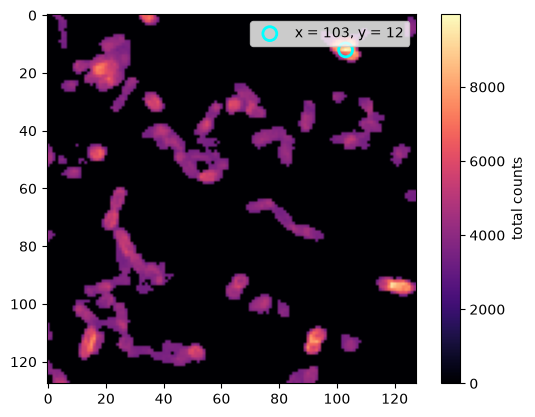

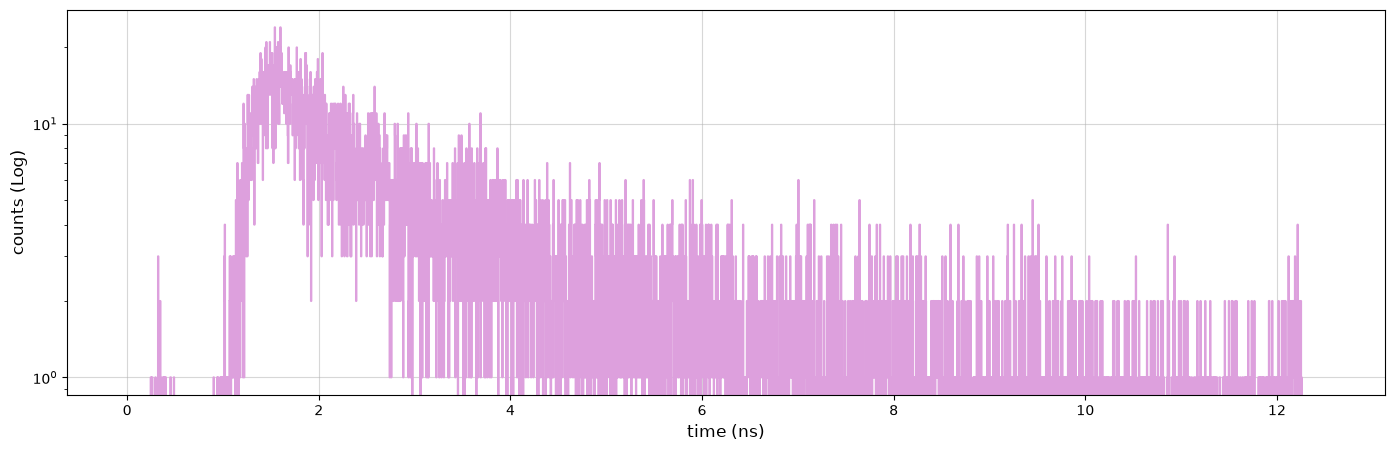

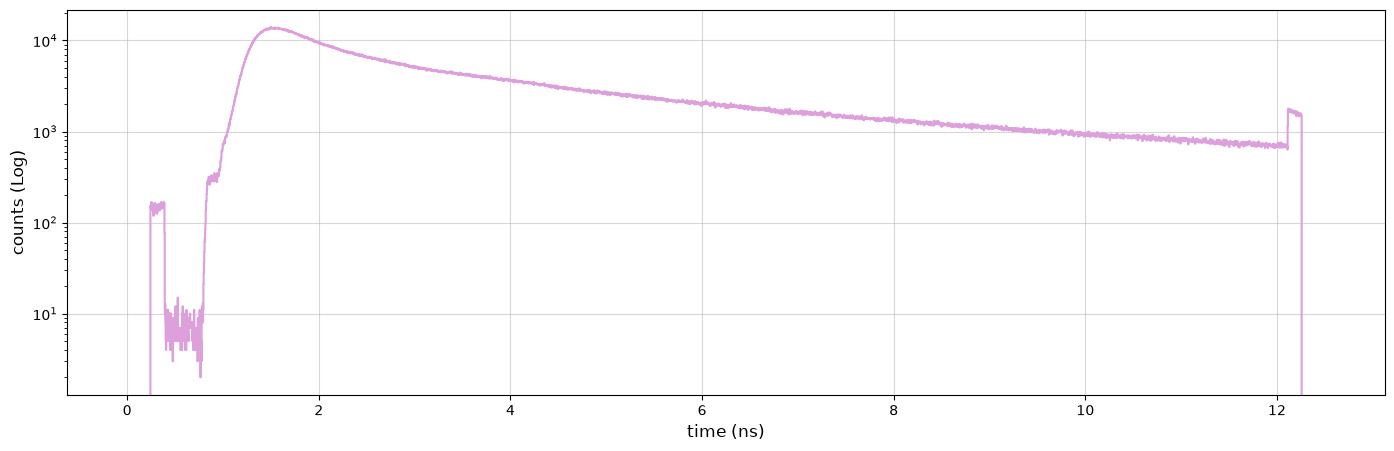

In [97]:
image = tiff.imread('./data/FLIM_4_flim_Ch1.tif')   # file name and path
max_pixel = image_flattener(image)

pixel_plot(image, max_pixel)    # pixel with highest count
global_image_plot(image)    # whole image

<h3> Flat image, pixel and total plot

Test on image from phasor.py (embryo of zebrafish)

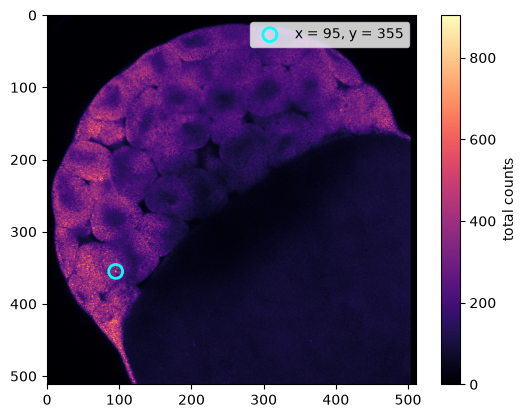

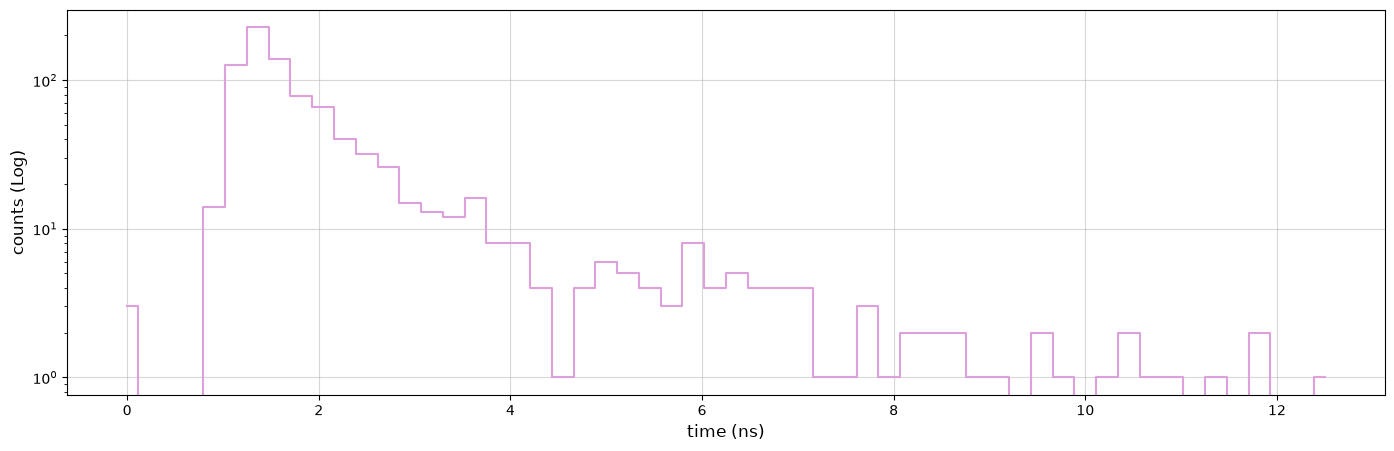

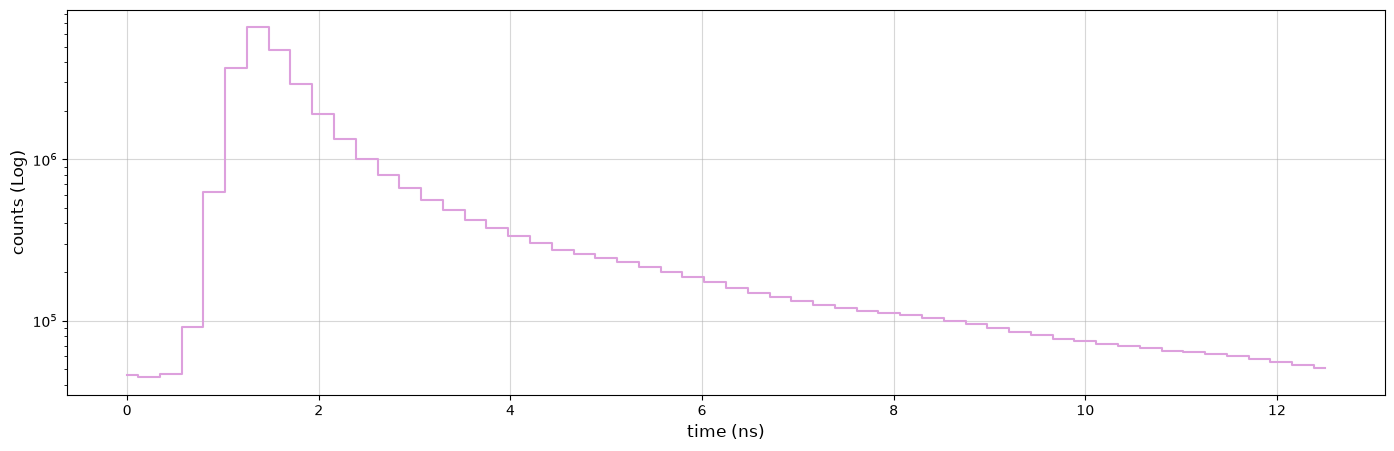

In [ ]:
# https://zenodo.org/records/8046636    # I got my data from here

embryopic = tiff.imread(fetch('Embryo.tif') )
fluopic = tiff.imread(fetch('Fluorescein_Embryo.tif'))

max_pixel1 = image_flattener(embryopic)
pixel_plot(embryopic, max_pixel1)
global_image_plot(embryopic)

<h3> Calibration flat image, pixel and total plot (fluorescein was used, with a known tau of 4ns)

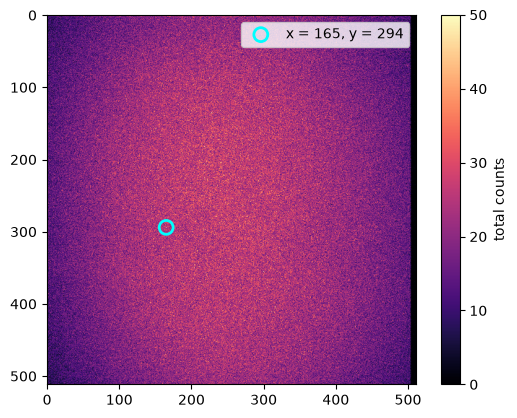

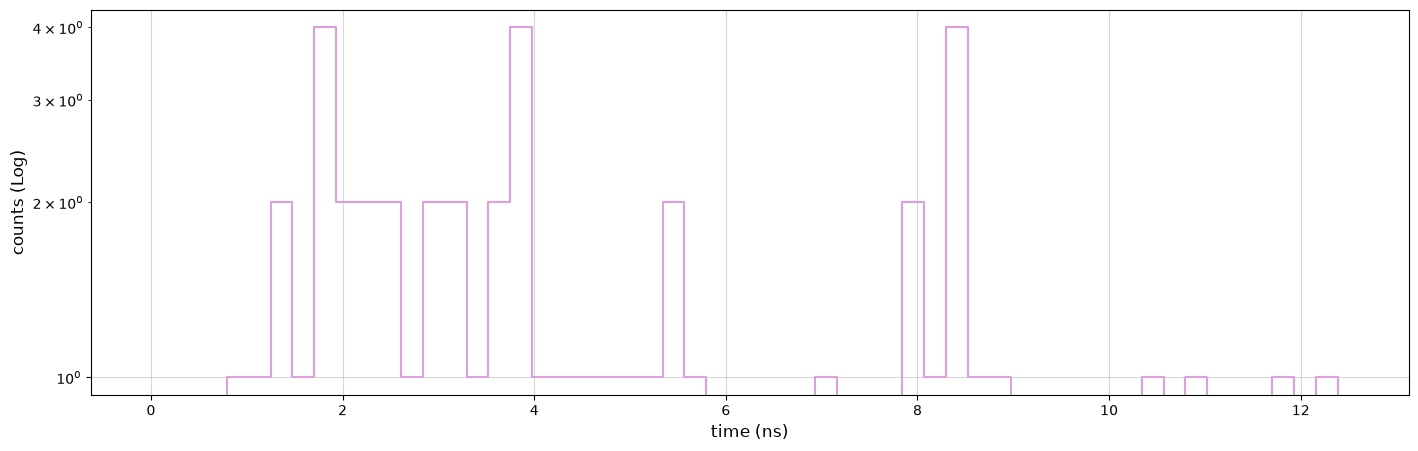

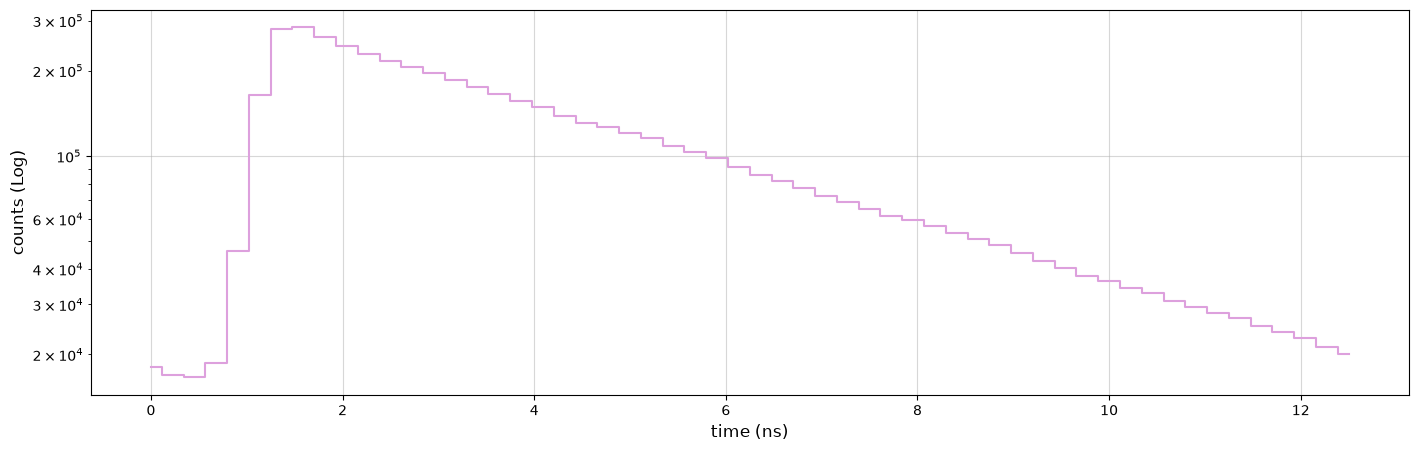

In [99]:
max_pixel2 = image_flattener(fluopic)
pixel_plot(fluopic, max_pixel2)
global_image_plot(fluopic)

<h3> IRF deconvolution

In [100]:
T_laser = 12.5
τ_fluor_true = 4.0      # LT of fluorescein (known value)    

G_irf, S_irf = extract_irf(fluopic, τ_fluor_true, T_laser)      # IRF from deconvolution
G_valid, S_valid = filter_image_phasors(embryopic, threshold_pct = 0.05)
G_clean, S_clean = phasor_deconv(G_valid, S_valid, G_irf, S_irf)    # deconvolution

Max count: 905 γ. Threshold: 45 γ.
Pixels over threshold: 193969/262144


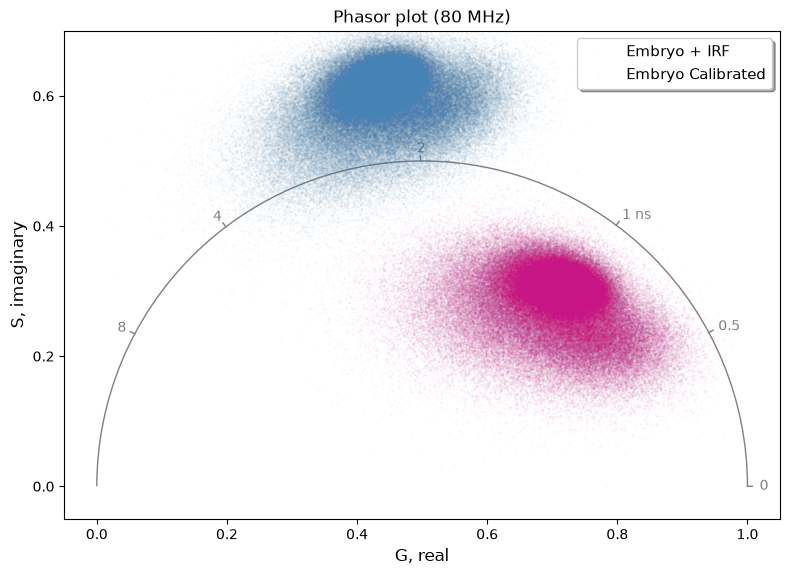

In [101]:
df_raw = pd.DataFrame({
    'G': G_valid,
    'S': S_valid,
    'Stato': '1. Raw'
})

df_clean = pd.DataFrame({
    'G': G_clean,
    'S': S_clean,
    'Stato': '2. Calibrated'
})

df_all = pd.concat([df_raw, df_clean], ignore_index = True)

points_comparison = [
    {
        'G': df_all[df_all['Stato'] == '1. Raw']['G'], 
        'S': df_all[df_all['Stato'] == '1. Raw']['S'], 
        'label': 'Embryo + IRF', 
        'color': 'steelblue', 
        'marker': '.', 
        'markersize': 1, 
        'alpha': 0.05, 
        'linestyle': 'None'
    },
    {
        'G': df_all[df_all['Stato'] == '2. Calibrated']['G'], 
        'S': df_all[df_all['Stato'] == '2. Calibrated']['S'], 
        'label': 'Embryo Calibrated', 
        'color': 'mediumvioletred', 
        'marker': '.', 
        'markersize': 1, 
        'alpha': 0.05, 
        'linestyle': 'None'
    }
]

universal_phasor_plot(T_laser = T_laser, points = points_comparison)

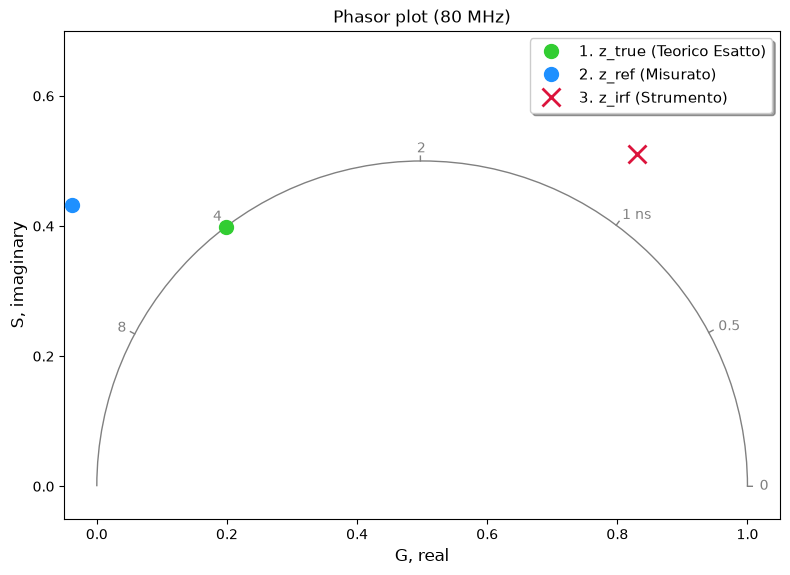

In [ ]:
# Note: z_ref = phasor from calibration sample, it's a single measured value
#       z_true = phasor calculated from fluorescine's true lifetime
#       z_irf = phasor obtained by de-convolving z_ref and z_true (working on the fluorescine only sample)

# This plot is just for error checking. I'm re-calculating stuff that was already done in functions but not returned

global_fluo = np.sum(fluopic, axis = (1, 2))        # calibration 2d array with total photon count per pixel
G_ref, S_ref = phasor_calc(global_fluo)           
# 
ω = 2 * np.pi / T_laser
ωτ = ω * τ_fluor_true
G_true_exact = 1 / (1 + ωτ**2)
S_true_exact = ωτ / (1 + ωτ**2)

points_calibration = [
    {
        'G': G_true_exact, 'S': S_true_exact,
        'label': '1. z_true (Teorico Esatto)', 
        'color': 'limegreen', 
        'marker': 'o', 
        'markersize': 10, 
        'alpha': 1.0, 
        'linestyle': 'None'
    },
    {
        'G': G_ref, 'S': S_ref, 
        'label': '2. z_ref (Misurato)', 
        'color': 'dodgerblue', 
        'marker': 'o',
        'markersize': 10, 
        'alpha': 1.0, 
        'linestyle': 'None'
    },
    {
        'G': G_irf, 'S': S_irf, 
        'label': '3. z_irf (Strumento)', 
        'color': 'crimson', 
        'marker': 'x',
        'markersize': 13, 
        'alpha': 1.0, 
        'mew': 2,
        'linestyle': 'None'
    }
]

universal_phasor_plot(T_laser = T_laser, points = points_calibration)


# z_ref = z_true * z_irf -> the angle of z_ref should be the sum of the angles of z_true and z_irf. Seems to be working fine